<a href="https://colab.research.google.com/github/ashah778/Data-201-Assignments/blob/main/Arnav_Shah_Week_8_HW_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loading the Hitters Dataset from the Week 8 Lab

In [49]:
# I am installing the ISLP
%pip -q install ISLP

In [50]:
# Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

In [51]:

# Load the Hitters dataset
hitters = load_data('Hitters')

# Remove rows with missing Salary
hitters = hitters.dropna(subset=['Salary']).copy()

# Set features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']  # thousands of dollars



In [52]:
# Seperating the information into numerical columns and categorical columns.
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Splitting the data into training and testing
# Using the training to build my model and the testing to evaluate its predictions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)


# Checking the amount of rows that went for each set
print(len(X), len(X_train), len(X_test))

# Creating a function to prepare the data before it comes in my Lasso model
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            # Standardizing the numerical columns for it to have a similar scale
            ('num', StandardScaler(), numeric_cols),
            # Converting the categories to numerical values for the model to implement
            ('cat', OneHotEncoder(
                handle_unknown='ignore', drop='first'
            ), category_cols)])

263 197 66


Part 1 - Experiment with α

In [53]:

# The 3 values the direction for the assingment says to compare the levels of regulation
alpha_values = [0.1, 10, 100]

# Created an empty list to store the results for the model
rows = []


In [54]:
# Built and trained a seperate lasso value for each alpha value

for a in alpha_values:
    pipe = Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', estimator.set_params(alpha=a))
    ])

    pipe.fit(X_train, y_train)

    # Getting the model coefficents to see the predictors that the model keeps
    coefs = pipe.named_steps['model'].coef_

    # Calculating the prediction errors and counting how many coefficents are nonzero
    rows.append({
        'alpha': a,
        'Training RMSE': np.sqrt(mean_squared_error(
            y_train, pipe.predict(X_train))),
        'Test RMSE': np.sqrt(mean_squared_error(
            y_test, pipe.predict(X_test))),
        'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6))  #count nonzero coefficients
    })

# Displaying the results to compare the three models
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))


,alpha,Training RMSE,Test RMSE,Nonzero coefficients
0,0.1,289.38,356.83,19
1,10.0,303.10,381.84,9
2,100.0,341.39,395.12,5


In [55]:
# Creating a model with alpha to see the remaining predictors
baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', estimator.set_params(alpha=a))
])
# Training the model through my training data
baseline.fit(X_train, y_train)


# Getting the feature name to identify the coefficent
feature_names = baseline.named_steps['preprocess'].get_feature_names_out()

# Organizing the predictor with the comparable Lasso coefficent
coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Lasso': baseline.named_steps['model'].coef_
})

# Displays the results for the predictors that have coefficents of zero
display(coef_table.round(2))

,Feature,Lasso
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


Questions:

1. As α increase what happens to the number of retained predictors ?

The thing that happens is as alpha increases the number of retained predictors decreases from 19 to 9 to 5 and the reason behind this is the Lasso ends up pushing more coefficients to zero. Since a higher alpha makes Lasso penalize the coefficients more that basically sets most of them to zero and removes a lot of predictors.

2. Does a smaller number of predictors always lead to a lower test RMSE ?


No I think a model with fewer predictors does not always have a lower test RMSE. In my results I found that the model that has alpha = 0.1 had the lowest test RMSE meanwhile I saw that alpha = 100 had the highest test RMSE.



Part 2 Visualize and Interpret

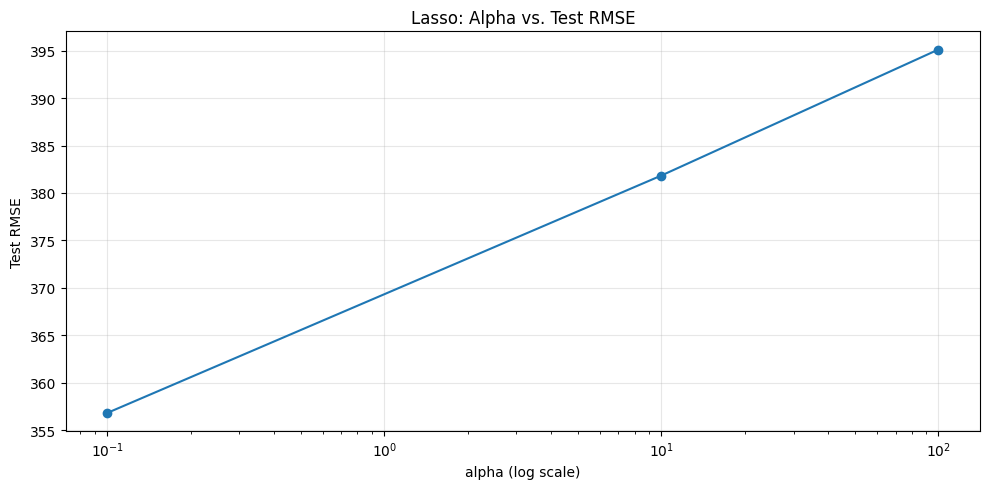

In [57]:
# Created a graph to show how alpha affects test RMSE.
fig, ax = plt.subplots(figsize=(10, 5))

# Plotted the alpha values and test RMSE
ax.semilogx(
    alpha_table['alpha'],
    alpha_table['Test RMSE'],
    marker='o'
)

# Adding the title and labels
ax.set_title('Lasso: Alpha vs. Test RMSE')
ax.set_xlabel('alpha (log scale)')
ax.set_ylabel('Test RMSE')
ax.grid(alpha=0.3)

# Showing the grid and displaying the graph
plt.tight_layout()
plt.show()


1) Which a produces the lowest test RMSE ?

I noticed that α = 0.1 produces the lowest test RMSE of 356.83. Although I cannot see the exact number on the graph and can only estimate it based on the range, my table shows the exact value. The graph also supports this result by showing that α = 0.1 has the lowest test RMSE.



2) Which a appears to cause the most underfitting? Explain using bias?

I notice that α = 100 produces a test RMSE of about 395.12. This shows that the model is underfitting the data. It appears to have the most underfitting due to the reduction in the number of predictors to 5.

I believe this also makes the model simpler and increases bias due to it being to simple to capture important patterns in the data. Bias is basically when the model has an error because the model is too simple.



3) Why might a model with higher training RMSE produce lower test RMSE?

I think a model with higher training RMSE might produce lower test RMSE since regularization helps prevent overfitting. Overfitting occurs when the model fits the training data too closely.

This assists the model in performing better on new data even despite not fitting the training data as closely.

Part 3 Model Interpretation

1. Identify two predictors that Lasso sets to zero at a = 100 ?

Lasso basically sets multiple predictors to zero at α = 100. Two examples are num_AtBat and nm_HmRun, which both have coefficients of 0.00 in my results.

2. Does setting their coefficents to zero prove that these predictors have no relationship with salary ?

No, I don't think a zero coefficient means that a predictor is unimportant. Based on the Week 8 lab, some predictors are correlated and share similar information. Due to this Lasso might keep a predictor and set another to zero due to the similar information which may be present.


3. If two models have similar test RMSE but one uses fewer predictors, which would you prefer? Explain your answer in terms of interpretability and predictive performance ?

My preference would be the model with fewer predictors because it is simpler and easier to interpret. If both models have a similar test RMSE, then the model with fewer predictors could provide a similar predictive performance with less complexity.

Predictive performance basically means the accuracy of how a model predicts results for new data. A lower test RMSE means the predictions are more accurate. This means that the model can make accurate predictions without needing so many predictors.

Part 4 - Choosing the Right Regression Model

Scenario A:

I choose Lasso as the right Regression Model since it adds a penalty to the absolute values of coefficients. This can also shrink some coefficients to zero by basically removing the predictors from the model.

The reason why I would choose Lasso is because there are 200 measurements but only 80 patients. It is benefical in finding smaller number of measurements that have value. This helps the model make better predictions while reducing overfitting. This happens when the model learns the training data and its noise very closely which is why it performs poor on data which is new.





Scenario B:

I choose Ridge because it implements a penalty to squared coefficients and makes it zero without removing the predictors. Ridge has a benefit since many predictors have a strong correlation and the company has a vision and belief that there is valuable information from implementing Ridge.

The company only wants the 40 predictors which is why choosing Ridge is the Right Regression Model.This can stabilize the model which prevents the predictors extremely large coefficents.

Scenario C:

I choose Ordinary Linear Regression as the right Regresion Model since it minimizes the training error without adding a penalty for large coefficients. Ordinary Linear Regresion has value when there are lot of observations and not many predictors.

The reason I would choose this model because there are 10,000 observations present with only three predictors. From the scenario I think it is linear which is why the model is stable and easy to interpret without needing to implement regularization.

Scenario D:

I choose Not Sure since the company has 500 observations and 25 predictors, but it is unclear and I am not sure how many predictors are benefical and useful and there is a lot of uncertainty about the strength of the correlation.


I think Ridge may work better if lot of the 25 predictors have value. This is because Ridge shrinks the coefficents towards zero without removing predictors. Meanwhile Lasso may work better if only a few are important.This is because Lasso can make less valuable predictors coefficents towards zero as well as it can remove it from the model. I think Ordinary Linear Regression might not perform well because it does not use a regularization penalty to control the coefficients. The negative factor is it could increase the chance of overfitting with 25 predictors.

This is the reason  why I would implement cross-validation to compare Ridge, Lasso, and Ordinary Linear Regression and choose the model with the lowest validation error. Cross-validation basically divides the training data into multiple sections and tests the model on different sections to understand the accuracy of it's performance. I think this would benefit the company in determining most accurate model that will make the most accurate predictions.